# Model Development

Walks through the same steps as `src/pipelines/training_pipeline.py`, but interactively: feature engineering, a seasonal-naive baseline, classical ML (Ridge / Random Forest / Gradient Boosting) with time-series-aware tuning, and the LSTM / Transformer sequence models, compared on the validation split.

Run `python -m src.pipelines.training_pipeline` from the repo root for the full, MLflow-logged run; this notebook mirrors it at a smaller scale for exploration.

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.data_ingestion.data_ingestion import (
    load_data, validate_schema, chronological_cutoffs,
    DATE_COLUMN, STORE_COLUMN, PRODUCT_COLUMN, TARGET_COLUMN, CATEGORICAL_COLUMNS,
)
from src.data_preprocessing.data_preprocessing import clean_data, clip_non_negative
from src.feature_engineering.feature_engineering import (
    add_calendar_features, add_lag_rolling_features, drop_lag_rolling_warmup,
    lag_rolling_feature_names, build_sequences, CALENDAR_FEATURES,
)
from src.models.baseline import SeasonalNaiveModel
from src.models.train_model import fit_and_score, hyperparameter_tuning, MODEL_TYPES
from src.models.sequence_models import train_sequence_model, predict_sequence_model
from src.models.predict_model import evaluate_forecast
from src.utils.helpers import load_config

config = load_config('../config.yaml')
data_cfg, train_cfg, fe_cfg = config['data'], config['training'], config['feature_engineering']

## Load, clean, engineer features

In [2]:
df = load_data('../data/raw/retail_store_inventory.csv')
validate_schema(df)

df = clean_data(df)
df = df.drop(columns=[c for c in data_cfg['excluded_features'] if c in df.columns])
df = add_calendar_features(df, DATE_COLUMN)
df = add_lag_rolling_features(df, [STORE_COLUMN, PRODUCT_COLUMN], TARGET_COLUMN,
                              fe_cfg['lag_days'], fe_cfg['rolling_windows'])

lag_rolling_cols = lag_rolling_feature_names(TARGET_COLUMN, fe_cfg['lag_days'], fe_cfg['rolling_windows'])
df = drop_lag_rolling_warmup(df, lag_rolling_cols)

numeric_cols = ['Price', 'Discount', 'Competitor Pricing', 'Holiday/Promotion'] + CALENDAR_FEATURES + lag_rolling_cols
categorical_cols = [c for c in CATEGORICAL_COLUMNS if c in df.columns] + [STORE_COLUMN, PRODUCT_COLUMN]
print(df.shape, len(numeric_cols), len(categorical_cols))

(70100, 28) 20 6


In [3]:
train_cutoff, val_cutoff = chronological_cutoffs(df[DATE_COLUMN], data_cfg['val_size'], data_cfg['test_size'])
train_df = df[df[DATE_COLUMN] <= train_cutoff].reset_index(drop=True)
val_df = df[(df[DATE_COLUMN] > train_cutoff) & (df[DATE_COLUMN] <= val_cutoff)].reset_index(drop=True)
test_df = df[df[DATE_COLUMN] > val_cutoff].reset_index(drop=True)
print(f'train={len(train_df)} val={len(val_df)} test={len(test_df)}  cutoffs={train_cutoff.date()} / {val_cutoff.date()}')

train=49100 val=10500 test=10500  cutoffs=2023-06-05 / 2023-09-18


## Seasonal-naive baseline

Predicts today's demand as the actual demand 7 days ago. Any model worth deploying must clear this bar.

In [4]:
naive = SeasonalNaiveModel(TARGET_COLUMN, lag=7)
naive_val_pred = clip_non_negative(naive.predict(val_df))
naive_metrics = evaluate_forecast(val_df[TARGET_COLUMN], naive_val_pred)
naive_metrics

{'mae': 120.45133333333334,
 'rmse': 155.04972136459355,
 'wape': 0.8788652862738776,
 'smape': 0.9328899580693693}

## Classical ML candidates

Ridge, Random Forest and Gradient Boosting on the tabular (lag/rolling/calendar) feature view.

In [5]:
classical_results = {}
for model_type in MODEL_TYPES:
    result = fit_and_score(
        model_type,
        train_df[numeric_cols + categorical_cols], train_df[TARGET_COLUMN],
        val_df[numeric_cols + categorical_cols], val_df[TARGET_COLUMN],
        numeric_cols, categorical_cols, train_cfg['random_state'],
    )
    metrics = evaluate_forecast(val_df[TARGET_COLUMN], clip_non_negative(result['val_predictions']))
    classical_results[model_type] = metrics
    print(f"{model_type:<20} {metrics}")

ridge                {'mae': 89.18225989040806, 'rmse': 109.56125976331771, 'wape': 0.6507125342666872, 'smape': 0.7212613866813739}


random_forest        {'mae': 90.45088761050572, 'rmse': 110.06028924148934, 'wape': 0.65996899356476, 'smape': 0.7254913381449598}


gradient_boosting    {'mae': 89.62220201792012, 'rmse': 109.56296611801031, 'wape': 0.6539225432648427, 'smape': 0.7224866626910206}


In [6]:
best_classical_type = min(classical_results, key=lambda m: classical_results[m]['wape'])
print('Best classical candidate:', best_classical_type)

tuned = hyperparameter_tuning(
    train_df[numeric_cols + categorical_cols], train_df[TARGET_COLUMN], best_classical_type,
    numeric_cols, categorical_cols, n_iter=15, random_state=train_cfg['random_state'],
)
tuned_pred = clip_non_negative(tuned['best_model'].predict(val_df[numeric_cols + categorical_cols]))
tuned_metrics = evaluate_forecast(val_df[TARGET_COLUMN], tuned_pred)
print('Tuned params:', tuned['best_params'])
print('Tuned val metrics:', tuned_metrics)

Best classical candidate: ridge


Tuned params: {'alpha': np.float64(0.012087541473056965)}
Tuned val metrics: {'mae': 89.18216294816351, 'rmse': 109.56129265108223, 'wape': 0.6507118269339318, 'smape': 0.721261189303958}


## LSTM and Transformer sequence models

Both consume the same (sequence_length, n_features) windows of lag/rolling/calendar/price features per (store, product) series and predict the next day's demand.

In [7]:
dl_feature_cols = numeric_cols
X_all, y_all, meta_all = build_sequences(
    df, dl_feature_cols, TARGET_COLUMN, [STORE_COLUMN, PRODUCT_COLUMN], DATE_COLUMN, fe_cfg['sequence_length'],
)
train_mask = (meta_all[DATE_COLUMN] <= train_cutoff).to_numpy()
val_mask = ((meta_all[DATE_COLUMN] > train_cutoff) & (meta_all[DATE_COLUMN] <= val_cutoff)).to_numpy()
print('sequences:', X_all.shape, 'train:', train_mask.sum(), 'val:', val_mask.sum())

sequences: (67100, 30, 20) train: 46100 val: 10500


In [8]:
sequence_results = {}
histories = {}
for model_type in ['lstm', 'transformer']:
    model, extras = train_sequence_model(
        model_type, X_all[train_mask], y_all[train_mask], X_all[val_mask], y_all[val_mask],
        train_cfg['deep_learning'], train_cfg['random_state'],
    )
    val_pred = clip_non_negative(predict_sequence_model(model, extras['scaler'], X_all[val_mask]))
    metrics = evaluate_forecast(y_all[val_mask], val_pred)
    sequence_results[model_type] = metrics
    histories[model_type] = extras['history']
    print(f"{model_type:<20} {metrics}")

lstm                 {'mae': 87.98117736889067, 'rmse': 110.23633860606222, 'wape': 0.6419489140982767, 'smape': 0.7196728221330331}


transformer          {'mae': 90.01511159261068, 'rmse': 109.5162006757117, 'wape': 0.6567893823133117, 'smape': 0.7231991597459662}


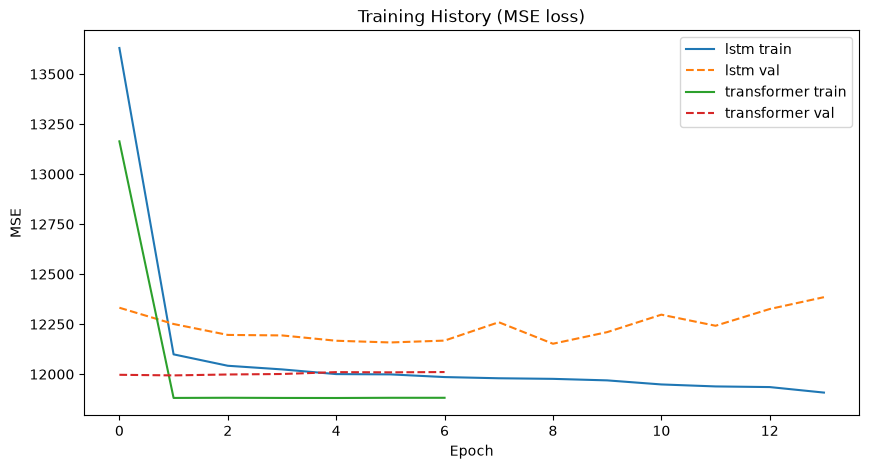

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
for model_type, history in histories.items():
    ax.plot(history['loss'], label=f'{model_type} train')
    ax.plot(history['val_loss'], linestyle='--', label=f'{model_type} val')
ax.set_title('Training History (MSE loss)')
ax.set_xlabel('Epoch')
ax.set_ylabel('MSE')
ax.legend()
plt.show()

## Validation comparison

All candidates on the same validation split, ranked by WAPE (the primary selection metric).

In [10]:
comparison = pd.DataFrame({
    'seasonal_naive': naive_metrics,
    f'classical ({best_classical_type}, tuned)': tuned_metrics,
    'lstm': sequence_results['lstm'],
    'transformer': sequence_results['transformer'],
}).T.sort_values('wape')
comparison

,mae,rmse,wape,smape
lstm,87.981177,110.236339,0.641949,0.719673
"classical (ridge, tuned)",89.182163,109.561293,0.650712,0.721261
transformer,90.015112,109.516201,0.656789,0.723199
seasonal_naive,120.451333,155.049721,0.878865,0.932890


See `model_evaluation.ipynb` for the final test-set evaluation of the selected model, and the README for the full discussion of why all four real models land within a hair of each other on this synthetic dataset.